# Imports

In [1]:
# Install project dependencies when running in a hosted/online notebook (Colab, Kaggle, etc.).
# Locally, ModifiedNEAT is imported via PRJ_DIR on sys.path (see the next cell), so this is a no-op there.
!pip install -U pip>21.2
!pip install -U "ModifiedNEAT[gpu] @ git+https://github.com/KshRaven/Modified-NEAT.git"
!pip install matplotlib

  Cloning https://github.com/KshRaven/Modified-NEAT.git to /tmp/pip-install-g4mi40_j/modifiedneat_9522bac850ea40e4b9f54f15e7a677d6
  Running command git clone --filter=blob:none --quiet https://github.com/KshRaven/Modified-NEAT.git /tmp/pip-install-g4mi40_j/modifiedneat_9522bac850ea40e4b9f54f15e7a677d6
  Resolved https://github.com/KshRaven/Modified-NEAT.git to commit 2bed5ce8ac73ee9c1c6fc0da972745500da9c865
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os, sys
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import math
import random
import warnings

from torch import Tensor
from numpy import ndarray as CPUArray
from typing import Union
from copy import deepcopy
from matplotlib.pyplot import Axes
from numba.core.errors import NumbaPerformanceWarning

PRJ_DIR = os.path.dirname(os.path.dirname(os.getcwd()))
if PRJ_DIR in ['c:\\', 'd:\\', '/']: PRJ_DIR = os.getcwd()
if PRJ_DIR not in sys.path: sys.path.insert(0, PRJ_DIR)
print(f"Project path = {PRJ_DIR}")

import ModifiedNEAT as meat
import ModifiedNEAT.nn as mnn
import ModifiedNEAT.optim as optim

from ModifiedNEAT import Population, Config
from ModifiedNEAT.nn.base import NeatModule
from ModifiedNEAT.util.datetime import clock, eta
from ModifiedNEAT.util.fancy_text import CM, Fore

warnings.filterwarnings("ignore", category=NumbaPerformanceWarning)

Project path = /content


In [3]:
DEVICE  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DTYPE   = torch.float32
meat.set_device(DEVICE, persist_env=False)
DEVICE, DTYPE, meat.get_device(), meat.get_tpb()

(device(type='cuda'), torch.float64, 'cuda', 10)

In [4]:
INT_MAPPING = {
    torch.float16: torch.int16,
    torch.float32: torch.int32,
    torch.float64: torch.int64,
    torch.bfloat16: torch.int16,
}
FLOAT_MAPPING = {v: k for k, v in INT_MAPPING.items()}

def get_int_dtype(type: torch.dtype):
    return INT_MAPPING.get(type, torch.long)

def get_float_dtype(type: torch.dtype):
    return FLOAT_MAPPING.get(type, torch.double)

# Data creation

In [5]:
def create_data(
    records: int, classes: int, base: int = 2, reverse: bool = False,
    normalize: bool = True, discrete: bool = False, randomize: bool = False,
    device: torch.device | str = 'cpu', dtype: torch.dtype = torch.float32,
    pad_len: int = 0, shift: bool = False, noise_prob: float = 0.0,
):
    _dtype = dtype if not discrete else get_int_dtype(dtype)
    labels = (
        torch.arange(records, device=device, dtype=get_int_dtype(dtype)) % classes
        if not randomize else
        torch.randint(0, classes, (records,), device=device, dtype=get_int_dtype(dtype))
    ).contiguous()
    enc_len = math.ceil(round(math.log(classes, base), 8))
    encodings = labels.to(_dtype).unsqueeze(-1).expand(labels.shape[0], enc_len).contiguous()
    # Compute base^i for each digit position i = 0, ..., enc_len-1 (least-significant first)
    powers = base ** torch.arange(enc_len, device=device, dtype=torch.int64)
    powers = (powers if reverse else powers.flip(0))
    # Extract each digit: floor(label / base^i) % base
    encodings = (torch.floor(encodings / powers) % base).to(_dtype)

    # -------------------- Complexify -------------------- #
    # Embed the true (enc_len-wide) digit pattern inside a longer sequence padded with random
    # "distractor" digits from the same alphabet, at a (optionally) randomized position, and
    # optionally corrupt individual digits with noise. This turns the task from "read off the
    # label directly from a fixed absolute position" (trivially solved by a per-position linear
    # readout) into "find/recognize a short motif that can appear anywhere in a noisy sequence" -
    # a local, translation-sensitive pattern-recognition problem that convolutional weight-sharing
    # is structurally suited for, unlike a plain fully-connected/linear model.
    if pad_len > 0:
        total_len = enc_len + pad_len
        # Distractor digits: uniform random symbols in the same alphabet as the real digits.
        canvas = torch.randint(0, base, (records, total_len), device=device, dtype=_dtype)
        if shift:
            offsets = torch.randint(0, pad_len + 1, (records,), device=device)
        else:
            offsets = torch.zeros(records, device=device, dtype=torch.int64)
        # Scatter the true enc_len-wide pattern into the canvas at each record's offset.
        col_idx = torch.arange(enc_len, device=device).unsqueeze(0) + offsets.unsqueeze(1)
        canvas.scatter_(1, col_idx, encodings)
        encodings = canvas

    if noise_prob > 0:
        # Randomly corrupt individual digits (anywhere in the sequence). Turns this into a
        # denoising / robust local-pattern-detection task rather than a clean lookup.
        flip_mask = torch.rand(encodings.shape, device=device) < noise_prob
        random_digits = torch.randint(0, base, encodings.shape, device=device, dtype=_dtype)
        encodings = torch.where(flip_mask, random_digits, encodings)

    if normalize and not discrete: encodings = (encodings / (base - 1) * 2) - 1
    return encodings, labels


In [6]:
for t in create_data(20, 8, 2, False, True, False): print(f"{t}\n{t.shape} | '{t.device}' | '{t.dtype}'")

tensor([[-1., -1., -1.],
        [-1., -1.,  1.],
        [-1.,  1., -1.],
        [-1.,  1.,  1.],
        [ 1., -1., -1.],
        [ 1., -1.,  1.],
        [ 1.,  1., -1.],
        [ 1.,  1.,  1.],
        [-1., -1., -1.],
        [-1., -1.,  1.],
        [-1.,  1., -1.],
        [-1.,  1.,  1.],
        [ 1., -1., -1.],
        [ 1., -1.,  1.],
        [ 1.,  1., -1.],
        [ 1.,  1.,  1.],
        [-1., -1., -1.],
        [-1., -1.,  1.],
        [-1.,  1., -1.],
        [-1.,  1.,  1.]])
torch.Size([20, 3]) | 'cpu' | 'torch.float32'
tensor([0, 1, 2, 3, 4, 5, 6, 7, 0, 1, 2, 3, 4, 5, 6, 7, 0, 1, 2, 3],
       dtype=torch.int32)
torch.Size([20]) | 'cpu' | 'torch.int32'


In [7]:
def tensor_memory(tensor: Tensor):
    """
    :param tensor: PyTorch tensor
    :return: Memory in Megabytes
    """
    return tensor.numel() * tensor.element_size() / (1024 ** 2)

# View data

In [8]:
def _add_bit_dividers(axis: Axes, num_bits: int, color='gray', linewidth=0.6, alpha=0.7):
    """Draw thin vertical lines between each bit-column (pixel boundaries)."""
    for i in range(1, num_bits):
        axis.axvline(i - 0.5, color=color, linewidth=linewidth, alpha=alpha)

def show_image(image: Tensor, title: str = None, size: tuple[int, int] = None, cmap='binary',
               axis: Axes = None, show_dividers: bool = True, divider_color='black', divider_width=2):
    if image.ndim == 1: image = image.unsqueeze(-2)
    features, columns = image.shape[-2:]
    image = torch.stack([image for _ in range(columns)], dim=-2)
    if size is None: size = (360, 360)
    if image.ndim == 3: image = image.permute(1, 2, 0)
    elif image.ndim == 2: pass
    else: raise ValueError(f"Unsupported ndim")
    image = image.cpu()
    created_axis = axis is None
    if axis is None:
        _, axis = plt.subplots(1, 1, figsize=(size[0] * 0.01, size[1] * 0.01))
    axis.imshow(image, cmap=cmap)
    if show_dividers:
        _add_bit_dividers(axis, columns, color=divider_color, linewidth=divider_width)
    if title is not None:
        axis.set_title(title)
    axis.set_axis_off()
    if created_axis:
        plt.show()

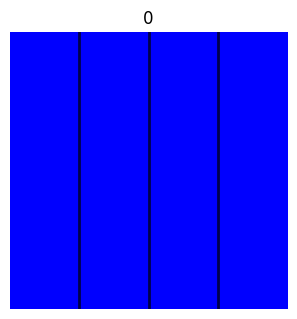

In [9]:
test_enc, test_lbl = [t[0] for t in create_data(records=1, classes=16, base=2)]
show_image(test_enc, test_lbl.item(), cmap='brg')

In [10]:
def show_batch(
    images: Tensor, predictions: Tensor = None, labels: Tensor = None, columns=8,
    size: tuple[int, int] = None, cmap='binary', no_axes=True,
    show_dividers: bool = True, divider_color='black', divider_width=2.0,
    compare: bool = False, base: int = 2, reverse: bool = False,
    normalize: bool = True, discrete: bool = False,
):
    # Only "compare" when we actually have predictions to turn into encodings
    compare_enabled = compare and predictions is not None

    def _to_visual(enc: Tensor, columns_: int) -> Tensor:
        if enc.ndim == 2: enc = enc.unsqueeze(-2)
        enc = torch.stack([enc for _ in range(columns_)], dim=-2)
        if enc.ndim == 4: enc = enc.permute(0, 2, 3, 1)
        elif enc.ndim == 3: pass
        else: raise ValueError(f"Unsupported ndim")
        return enc.cpu()

    # enc_len / columns_ (bit-width) comes from the raw encoding width, before visual expansion
    enc_len = images.shape[-1]
    columns_ = enc_len
    images_vis = _to_visual(images, columns_)

    if size is None: size = (720, 1080)

    predicted_vis = None
    if compare_enabled:
        # Reconstruct the predicted encodings the same way create_data does, so they're
        # directly visually comparable to the actual/expected encodings above them.
        _dtype = images.dtype if not discrete else get_int_dtype(images.dtype)
        pred_labels = predictions.to(images.device)
        pred_enc = pred_labels.to(_dtype).unsqueeze(-1).expand(pred_labels.shape[0], enc_len).contiguous()
        powers = base ** torch.arange(enc_len, device=images.device, dtype=torch.int64)
        powers = powers if reverse else powers.flip(0)
        pred_enc = (torch.floor(pred_enc / powers) % base).to(_dtype)
        if normalize and not discrete: pred_enc = pred_enc / (base - 1)
        predicted_vis = _to_visual(pred_enc, columns_)

    n = images_vis.shape[0]
    rows_data = math.ceil(n / columns)
    row_mult = 2 if compare_enabled else 1

    fig, axes = plt.subplots(
        rows_data * row_mult, columns,
        figsize=(size[1] * 0.01, size[0] * 0.01 * row_mult)
    )
    if isinstance(axes, CPUArray):
        axes = axes.flatten()
    else:
        axes = [axes]

    def _draw(axis, image, title):
        axis.imshow(image, cmap=cmap)
        if show_dividers:
            _add_bit_dividers(axis, columns_, color=divider_color, linewidth=divider_width)
        if title:
            axis.set_title(title)
        if no_axes:
            axis.set_axis_off()

    axis_index = 0
    for row_start in range(0, n, columns):
        row_end = min(row_start + columns, n)

        # Row of actual/expected encodings
        for i in range(row_start, row_end):
            title = ''
            if labels is not None:
                title += f"L={labels[i].cpu().item()}"
            if not compare_enabled and predictions is not None:
                title += f"{' ' if title else ''}P={predictions[i].cpu().item()}"
            _draw(axes[axis_index], images_vis[i], title)
            axis_index += 1
        for _ in range(row_end, row_start + columns):
            axes[axis_index].set_axis_off()
            axis_index += 1

        # Matching row of predicted encodings, right below
        if compare_enabled:
            for i in range(row_start, row_end):
                title = f"P={predictions[i].cpu().item()}"
                _draw(axes[axis_index], predicted_vis[i], title)
                axis_index += 1
            for _ in range(row_end, row_start + columns):
                axes[axis_index].set_axis_off()
                axis_index += 1

    plt.show()

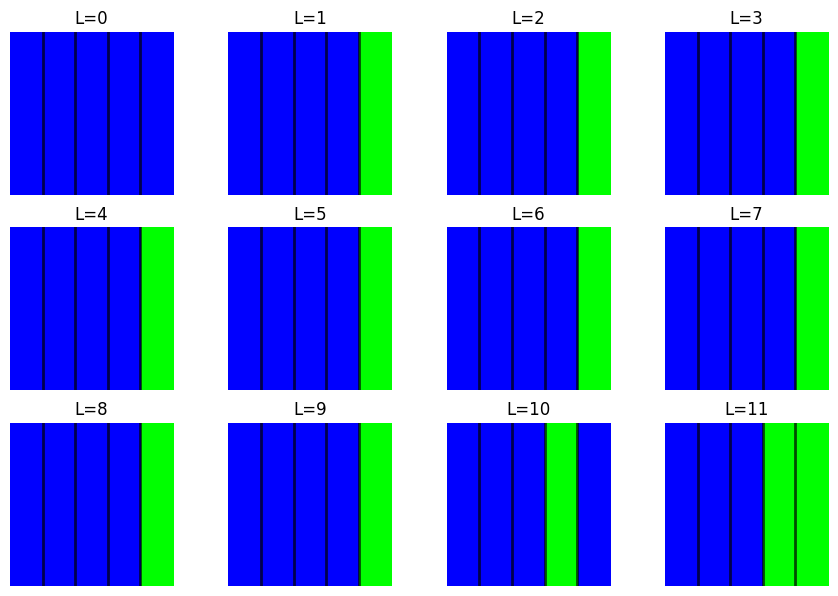

In [11]:
test_enc, test_lbl = create_data(records=12, classes=100_000, base=10)
show_batch(test_enc, labels=test_lbl, cmap='brg', columns=4)

# Model Architecture

In [12]:
def model_size(model: meat.NeatModule):
    return np.sum([param.numel() * param.element_size() for param in model.parameters()]) / (1024 ** 2)

def model_params(model: meat.NeatModule):
    return np.sum([param.numel() for param in model.parameters()])

In [13]:
class ConvNetwork(meat.NeatModule):
    def __init__(
        self, inputs: int, outputs: int, dim_size: int, kernel_size: int, seq_len: int, layers: int,
        vocab_size: int | None = None, groups=1, epsilon=1e-12, bias=True, device='cpu', dtype=torch.float32
    ):
        super().__init__()

        self.inputs         = inputs
        self.outputs        = outputs
        self.dim_size       = dim_size
        self.kernel_size    = kernel_size
        self.seq_len        = seq_len
        self.layers         = layers
        self.vocab_size     = vocab_size
        self.groups         = groups
        self.epsilon        = epsilon
        self.bias           = bias
        self.device         = device
        self.dtype          = dtype

        self.pool_stride    = 1

        # Input projection
        sequence = [ # Expected shape(genomes, *batch_size, features=1, sequence)
            (
                mnn.Conv1d(inputs, dim_size, 1, bias=True, device=device, dtype=dtype)
                if vocab_size is None else
                mnn.Sequential(
                    mnn.Embedding(vocab_size, dim_size, device=device, dtype=dtype),
                    mnn.Transpose()
                )
            ),
            # mnn.BatchNorm1d(dim_size, device=device, dtype=dtype),
            nn.SiLU(),
            mnn.Conv1d(dim_size, dim_size, kernel_size, padding=-1, bias=bias, device=device, dtype=dtype),
            # NOTE: Pooling is on hold (not needed for this simple test), so the sequence length is kept (pool_stride=1).
            #       To bring it back: set pool_stride=2 and use a custom NEAT MaxPooling or normal torch modules
            #       (see mnn.Transpose(...), mnn.Permute(...)).
            # TODO: Verify structuraly if normalization is necessary in first step or at all
            # mnn.GroupNorm(groups, dim_size, epsilon, True, bias=False, device=device, dtype=dtype),
            # mnn.BatchNorm1d(dim_size, device=device, dtype=dtype),
            # nn.SiLU(),
            # mnn.MaxPool1d(2, stride=self.pool_stride, padding=-1), # on hold, see NOTE above
            nn.SiLU(),
        ]
        # Deep neural network
        for layer_idx in range(layers):
            sequence.extend([ # Expected shape(genomes, *batch_size, dim_size, sequence)
                mnn.Conv1d(dim_size, dim_size, kernel_size, padding=-1, bias=bias, device=device, dtype=dtype),
                # TODO: Verify structuraly if groups should be added to convolution
                # mnn.GroupNorm(groups, dim_size, epsilon, True, bias=False, device=device, dtype=dtype),
                # TODO: Verify structuraly if normalization is done before or after activation or convolution
                # mnn.BatchNorm1d(dim_size, device=device, dtype=dtype),
                # NOTE: For now ignore normalization
                nn.SiLU(),
            ])
        # Output projection
        sequence.extend([ # in=(genomes, *batch_size, dim_size, sequence) out=(genomes, *batch_size, classes)
            mnn.Transpose(),
            nn.Flatten(start_dim=-2),
            # NOTE: Average pooling removed - we now flatten the (dim_size, sequence) block directly and
            #       project the full flattened vector, so no information is averaged away.
            mnn.Linear(dim_size * seq_len // self.pool_stride, dim_size, bias=bias, device=device, dtype=dtype),
            # mnn.RMSNorm(dim_size, device=device, dtype=dtype),
            nn.SiLU(),
            mnn.Linear(dim_size, outputs, bias=True, device=device, dtype=dtype),
        ])

        self.sequence = mnn.Sequential(*sequence)

    def forward(self, tensor: Tensor, keys: Union[int, list[int]] = None, verbose: int = None):
        tensor = self.sequence(tensor, keys=keys, verbose=verbose)
        return tensor

    def evaluate(
        self, tensor: Tensor, keys: Union[int, list[int]] = None, verbose: int = None,
        deterministic: bool = True
    ):
        """Class predictions. deterministic=True -> argmax, False -> sample from softmax(logits)."""
        logits = self(tensor, keys=keys, verbose=verbose)
        if deterministic:
            return torch.argmax(logits, dim=-1)
        return torch.distributions.Categorical(logits=logits).sample()


class LinNetwork(meat.NeatModule):
    """Fully-connected counterpart to ConvNetwork, used as a baseline to compare against."""

    def __init__(
        self, inputs: int, outputs: int, seq_len: int, dim_size: int, layers: int,
        vocab_size: int | None = None, bias=True, device='cpu', dtype=torch.float32
    ):
        super().__init__()

        self.inputs      = inputs
        self.outputs     = outputs
        self.seq_len     = seq_len
        self.dim_size    = dim_size
        self.layers      = layers
        self.vocab_size  = vocab_size
        self.bias        = bias
        self.device      = device
        self.dtype       = dtype

        # Input projection:
        sequence = [
            # out=(genomes, *batch_size, seq_len, features=1)
            (
                mnn.Sequential(
                    mnn.Transpose(),
                    mnn.Linear(inputs, dim_size, bias=True, device=device, dtype=dtype),
                )
                if vocab_size is None else
                mnn.Sequential(
                    mnn.Embedding(vocab_size, dim_size, device=device, dtype=dtype),
                )
            ),
            # mnn.RMSNorm(dim_size, device=device, dtype=dtype),
            nn.SiLU(),
            mnn.Linear(dim_size, dim_size, bias=bias, device=device, dtype=dtype),
            # mnn.RMSNorm(dim_size, device=device, dtype=dtype),
            nn.SiLU(),
        ]

        # Deep neural network, matching ConvNetwork's `layers` count for a fair comparison
        for layer_idx in range(layers):
            sequence.extend([
                mnn.Linear(dim_size, dim_size, bias=bias, device=device, dtype=dtype),
                # mnn.RMSNorm(dim_size, device=device, dtype=dtype),
                nn.SiLU(),
            ])

        # Output projection: flatten (features, sequence) into a single vector per record
        sequence.extend([
            nn.Flatten(start_dim=-2),
            mnn.Linear(dim_size * seq_len, dim_size, bias=bias, device=device, dtype=dtype),
            # mnn.RMSNorm(dim_size, device=device, dtype=dtype),
            nn.SiLU(),
            mnn.Linear(dim_size, outputs, bias=True, device=device, dtype=dtype),
        ])

        self.sequence = mnn.Sequential(*sequence)

    def forward(self, tensor: Tensor, keys: Union[int, list[int]] = None, verbose: int = None):
        return self.sequence(tensor, keys=keys)

    def evaluate(
        self, tensor: Tensor, keys: Union[int, list[int]] = None, verbose: int = None,
        deterministic: bool = True
    ):
        """Class predictions. deterministic=True -> argmax, False -> sample from softmax(logits)."""
        logits = self(tensor, keys=keys, verbose=verbose)
        if deterministic:
            return torch.argmax(logits, dim=-1)
        return torch.distributions.Categorical(logits=logits).sample()


In [14]:
test_inputs = torch.randn(1, 10, 3, 16, dtype=DTYPE)
test_model = ConvNetwork(
    inputs=3, outputs=10, kernel_size=3, dim_size=64, seq_len=16,
    layers=2, bias=False, device='cpu', dtype=DTYPE
)
print(test_model)
print(f"Genomes={test_model.genome_num}, Parameters={model_params(test_model)}, Size={model_size(test_model):.4f} MB")
with torch.no_grad():
    test_outputs = test_model.evaluate(test_inputs, verbose=2)
    test_guess = test_model.evaluate(test_inputs, deterministic=False)
    # test_model.save()
    # test_model.load()
test_outputs, test_guess, test_outputs.shape

ConvNetwork(
  (sequence): Sequential[NeatModule](
    (0): Conv1d[NeatModule](channels_in=3, channels_out=64, kernel_size=(1,), stride=1, padding=(0,), dilation=1, groups=1, bias=True, padding_mode=zeros)
    (1): SiLU()
    (2): Conv1d[NeatModule](channels_in=64, channels_out=64, kernel_size=(3,), stride=1, padding=(1,), dilation=1, groups=1, bias=False, padding_mode=zeros)
    (3): SiLU()
    (4): Conv1d[NeatModule](channels_in=64, channels_out=64, kernel_size=(3,), stride=1, padding=(1,), dilation=1, groups=1, bias=False, padding_mode=zeros)
    (5): SiLU()
    (6): Conv1d[NeatModule](channels_in=64, channels_out=64, kernel_size=(3,), stride=1, padding=(1,), dilation=1, groups=1, bias=False, padding_mode=zeros)
    (7): SiLU()
    (8): Transpose(dim0=-1, dim1=-2)
    (9): Flatten(start_dim=-2, end_dim=-1)
    (10): Linear[NeatModule](inputs=1024, outputs=64, bias=False)
    (11): SiLU()
    (12): Linear[NeatModule](inputs=64, outputs=10, bias=True)
  )
)
Genomes=None, Parameters=10

(tensor([[4, 5, 7, 3, 8, 4, 0, 4, 7, 2]]),
 tensor([[4, 5, 7, 3, 8, 4, 0, 4, 7, 2]]),
 torch.Size([1, 10]))

# Population creation

In [15]:
def create_population(
    module: NeatModule, genomes: int, config: Config = None,
    reporter: bool = False, verbose: bool | int = False
):
    population = Population(genomes, module, config, init_rep=reporter, verbose=verbose)
    return population

In [16]:
test_population = create_population(ConvNetwork(1, 10, 16, 3, 64, 1), 20, reporter=True, verbose=2)
print(test_population.modules)
test_model = list(test_population.modules.values())[0]
test_model.genome_num, test_model

/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 4 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 20 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 2 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


Initialized genomes in  in 2.38s


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 8 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 64 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 4 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


Ran distance kernel in 0.45 s
Created distances cache in 5.8 s
Collected species representatives in 6.52 s
Filled species in 2.62 s
Updated species mapping in 0.91 s
Completed speciating in 15.84 s
Mean genetic distance 0.048, standard deviation 0.022, with 1 species
{0: ConvNetwork(
  (sequence): Sequential[NeatModule](
    (0): Conv1d[NeatModule](channels_in=1, channels_out=16, kernel_size=(1,), stride=1, padding=(0,), dilation=1, groups=1, bias=True, padding_mode=zeros)
    (1): SiLU()
    (2): Conv1d[NeatModule](channels_in=16, channels_out=16, kernel_size=(3,), stride=1, padding=(1,), dilation=1, groups=1, bias=True, padding_mode=zeros)
    (3): SiLU()
    (4): Conv1d[NeatModule](channels_in=16, channels_out=16, kernel_size=(3,), stride=1, padding=(1,), dilation=1, groups=1, bias=True, padding_mode=zeros)
    (5): SiLU()
    (6): Transpose(dim0=-1, dim1=-2)
    (7): Flatten(start_dim=-2, end_dim=-1)
    (8): Linear[NeatModule](inputs=1024, outputs=16, bias=True)
    (9): SiLU()
  

(20,
 ConvNetwork(
   (sequence): Sequential[NeatModule](
     (0): Conv1d[NeatModule](channels_in=1, channels_out=16, kernel_size=(1,), stride=1, padding=(0,), dilation=1, groups=1, bias=True, padding_mode=zeros)
     (1): SiLU()
     (2): Conv1d[NeatModule](channels_in=16, channels_out=16, kernel_size=(3,), stride=1, padding=(1,), dilation=1, groups=1, bias=True, padding_mode=zeros)
     (3): SiLU()
     (4): Conv1d[NeatModule](channels_in=16, channels_out=16, kernel_size=(3,), stride=1, padding=(1,), dilation=1, groups=1, bias=True, padding_mode=zeros)
     (5): SiLU()
     (6): Transpose(dim0=-1, dim1=-2)
     (7): Flatten(start_dim=-2, end_dim=-1)
     (8): Linear[NeatModule](inputs=1024, outputs=16, bias=True)
     (9): SiLU()
     (10): Linear[NeatModule](inputs=16, outputs=10, bias=True)
   )
 ))

# Initialization

In [17]:
RECORDS     = 200
SPLIT       = 0.70
CLASSES     = 9
BASE        = 3
NORMALIZE   = True
DISCRETE    = False
REVERSED    = False

# ---- Data complexity knobs (consumed by create_data, see get_records below) ---- #
# Without these, each record is just the label's digits sitting at a fixed absolute
# position - trivially linearly separable (one linear readout per digit position),
# which is why LinNetwork was winning. These knobs hide the same digit pattern inside
# a longer, noisy sequence at a (possibly) random offset, turning the task into local
# motif detection - something convolutional weight-sharing has a structural edge on.
PAD_LEN     = 7      # extra distractor positions appended to the true digit encoding
SHIFT       = False  # randomize the position of the true encoding within the padded sequence
NOISE_PROB  = 0.05   # probability that any single digit (real or distractor) gets corrupted

SEQ_LEN     = math.ceil(round(math.log(CLASSES, BASE), 8)) + PAD_LEN
print(SEQ_LEN)


9


In [18]:
GENOMES     = 100
CONFIG      = Config("binary", "tests")
CONFIG.genome.init_type                 = 'normal'
CONFIG.genome.weight_init_mean          = 0.0
CONFIG.genome.weight_init_std           = 0.20
CONFIG.genome.weight_min_value          = -math.inf
CONFIG.genome.weight_max_value          = +math.inf
CONFIG.genome.weight_mutate_power       = 0.075
CONFIG.genome.weight_mutate_rate        = 0.65
CONFIG.genome.weight_replace_rate       = 0.00
CONFIG.genome.weight_add_prob           = 0.99
CONFIG.genome.weight_del_prob           = 0.00
CONFIG.reproduction.min_species_size    = GENOMES
CONFIG.reproduction.purge               = 1
CONFIG.reproduction.survival_threshold  = 0.10
CONFIG.reproduction.clone_threshold     = 0.50
CONFIG.reproduction.darwin_multiplier   = 0.50
CONFIG.reproduction.elitism             = 0.33
CONFIG.genome.compatibility_disjoint_coefficient = 1.0
CONFIG.genome.compatibility_weight_coefficient = 0.5
CONFIG.species.compatibility_threshold  = math.inf
CONFIG.stagnation.max_stagnation        = 1
CONFIG.stagnation.species_elitism       = 1
print(f"Config path = {CONFIG.path}")
CONFIG.save()
CONFIG.load(2)

SCHEDULERS = [
    optim.scheduler.CosineAnnealing(CONFIG, 20, 0.01, ['weight_mutate_power', 'weight_init_std'], warm=True, log=True),
    # # optim.scheduler.CosineAnnealing(CONFIG, 10, 0.75, 'weight_mutate_rate', True, True),
    # optim.scheduler.CosineAnnealing(CONFIG, 50, 0.33, 'weight_replace_rate', True, True),
]

Config path = tests/binary.mnc.json
Created configuration 'GENERAL CONFIG' in NEAT Configuration binary.mnc.json
Created configuration 'GENOME CONFIG' in NEAT Configuration binary.mnc.json
Created configuration 'SPECIES CONFIG' in NEAT Configuration binary.mnc.json
Created configuration 'STAGNATION CONFIG' in NEAT Configuration binary.mnc.json
Created configuration 'REPRODUCTION CONFIG' in NEAT Configuration binary.mnc.json
Created configuration 'RL CONFIG' in NEAT Configuration binary.mnc.json
fitness_criterion         = max
fitness_threshold         = inf
pop_size                  = 100
reset_on_extinction       = True
seed                      = 942839
Loaded configuration 'GENERAL CONFIG' in NEAT Configuration binary.mnc.json
weight_init_mean          = 0.0
weight_init_std           = 0.2
weight_max_value          = inf
weight_min_value          = -inf
weight_mutate_power       = 0.075
weight_mutate_rate        = 0.65
weight_replace_rate       = 0.0
weight_add_prob           = 0.99

In [19]:
def get_records(genomes: int, split: float):
    assert 0 < split < 1
    records_train = round(RECORDS * split)
    records_eval = RECORDS - records_train
    assert records_train > 0 and records_eval > 0
    records = [
        create_data(
            l, CLASSES, BASE, REVERSED, NORMALIZE, DISCRETE, False, device='cpu', dtype=DTYPE,
            pad_len=PAD_LEN, shift=SHIFT, noise_prob=NOISE_PROB,
        )
        for l in [records_train, records_eval]
    ]

    def add_feature(tensor): return tensor.unsqueeze(-2)
    def nothing(tensor): return tensor

    # NOTE: The Conv1d input branch expects a (features, sequence) layout, so encodings get an
    #       extra singleton feature dim added. The Embedding input branch (used when DISCRETE=True)
    #       expects plain (sequence,) integer token ids instead, so we must NOT add that extra
    #       dim in the discrete case or the embedding lookup / downstream Conv1d shapes break.
    encoding_transform = nothing if DISCRETE else add_feature

    return tuple(
        tuple(
            g(t.unsqueeze(0).repeat_interleave(genomes, dim=0).to(DEVICE))
            for t, g in zip(d, [encoding_transform, nothing])
        )
        for d in records
    )

(train_inp, train_out), (eval_inp, eval_out) = train_data, eval_data = get_records(GENOMES, SPLIT)


In [20]:
train_inp[:4, :3], train_out[:4, :3], train_inp.shape, train_out.shape, eval_out.shape

(tensor([[[[-1., -1.,  1.,  0.,  0.,  0., -1.,  0., -1.]],
 
          [[-1.,  0.,  0.,  1.,  1.,  0., -1.,  0.,  0.]],
 
          [[-1.,  1., -1., -1.,  0.,  0., -1.,  0.,  0.]]],
 
 
         [[[-1., -1.,  1.,  0.,  0.,  0., -1.,  0., -1.]],
 
          [[-1.,  0.,  0.,  1.,  1.,  0., -1.,  0.,  0.]],
 
          [[-1.,  1., -1., -1.,  0.,  0., -1.,  0.,  0.]]],
 
 
         [[[-1., -1.,  1.,  0.,  0.,  0., -1.,  0., -1.]],
 
          [[-1.,  0.,  0.,  1.,  1.,  0., -1.,  0.,  0.]],
 
          [[-1.,  1., -1., -1.,  0.,  0., -1.,  0.,  0.]]],
 
 
         [[[-1., -1.,  1.,  0.,  0.,  0., -1.,  0., -1.]],
 
          [[-1.,  0.,  0.,  1.,  1.,  0., -1.,  0.,  0.]],
 
          [[-1.,  1., -1., -1.,  0.,  0., -1.,  0.,  0.]]]], device='cuda:0',
        dtype=torch.float64),
 tensor([[0, 1, 2],
         [0, 1, 2],
         [0, 1, 2],
         [0, 1, 2]], device='cuda:0'),
 torch.Size([100, 140, 1, 9]),
 torch.Size([100, 140]),
 torch.Size([100, 60]))

In [21]:
INPUTS      = 1
OUTPUTS     = CLASSES
EMBED_SIZE  = 48
KERNEL_SIZE = 3
# NOTE: FC_SIZE dependant on NoOfBits * DimSize
VOCAB_SIZE  = None if not DISCRETE else BASE
LAYERS      = 2
GROUPS      = 1
BIAS        = False
assert KERNEL_SIZE <= SEQ_LEN
SEQ_LEN

9

In [22]:
CONV_MODEL = ConvNetwork(
    INPUTS, OUTPUTS, EMBED_SIZE, KERNEL_SIZE, SEQ_LEN,
    LAYERS, VOCAB_SIZE, GROUPS, bias=BIAS,
    device=DEVICE, dtype=DTYPE
)
CONV_POPULATION = create_population(CONV_MODEL, GENOMES, CONFIG)
print(f"Genomes={CONV_MODEL.genome_num}, Parameters={model_params(CONV_MODEL)}, Size={model_size(CONV_MODEL):.4f} MB")
CONV_MODEL

/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 50 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 10 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 100 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


Genomes=100, Parameters=4200900, Size=32.0503 MB


ConvNetwork(
  (sequence): Sequential[NeatModule](
    (0): Conv1d[NeatModule](channels_in=1, channels_out=48, kernel_size=(1,), stride=1, padding=(0,), dilation=1, groups=1, bias=True, padding_mode=zeros)
    (1): SiLU()
    (2): Conv1d[NeatModule](channels_in=48, channels_out=48, kernel_size=(3,), stride=1, padding=(1,), dilation=1, groups=1, bias=False, padding_mode=zeros)
    (3): SiLU()
    (4): Conv1d[NeatModule](channels_in=48, channels_out=48, kernel_size=(3,), stride=1, padding=(1,), dilation=1, groups=1, bias=False, padding_mode=zeros)
    (5): SiLU()
    (6): Conv1d[NeatModule](channels_in=48, channels_out=48, kernel_size=(3,), stride=1, padding=(1,), dilation=1, groups=1, bias=False, padding_mode=zeros)
    (7): SiLU()
    (8): Transpose(dim0=-1, dim1=-2)
    (9): Flatten(start_dim=-2, end_dim=-1)
    (10): Linear[NeatModule](inputs=432, outputs=48, bias=False)
    (11): SiLU()
    (12): Linear[NeatModule](inputs=48, outputs=9, bias=True)
  )
)

In [23]:
test_pred = CONV_MODEL.evaluate(eval_inp, verbose=2)
test_pred[:4, :3], test_pred.shape

(tensor([[3, 3, 4],
         [3, 1, 3],
         [2, 6, 6],
         [0, 6, 0]], device='cuda:0'),
 torch.Size([100, 60]))

# Train convolutional model

In [24]:
BATCH_SIZE      = 256
USE_ACCURACY    = False
EPOCHS          = 500

In [25]:
def get_batches(records: int, batch_size: int = None, shuffle=False):
    if batch_size is None:
        batch_size = records
    assert records > 0
    if batch_size is None:
        batch_size = records
    else:
        assert batch_size > 0
        batch_size = min(batch_size, records)

    indices: list[int] = list(range(records))
    if shuffle:
        random.shuffle(indices)
    batch_indices: list[list[int]] = list()
    batch: list[int] = list()
    for i, index in enumerate(indices):
        batch.append(index)
        batch_is_filled = len(batch) == batch_size
        no_more_records = i == len(indices) - 1 and not batch_is_filled
        if batch_is_filled or no_more_records:
            batch_indices.append(batch)
            batch = list()

    return batch_indices

In [26]:
@torch.no_grad() # NOTE: Just in case parameters have gradients enabled
def get_accuracy(
    population: Population, inputs: Tensor, outputs: Tensor,
    batch_size: int, deterministic: bool = True, verbose: bool | int = False,
    keys: Union[int, list[int], None] = None, mean: bool = False
):
    model = list(population.modules.values())[0]
    if keys is not None and not isinstance(keys, (tuple, list)):
        keys = [keys]
    if keys is not None:
        mapping = population.get_mapping()
        key_indices = [mapping[key] for key in keys]
        inputs, outputs = inputs[key_indices], outputs[key_indices]

    torch.cuda.empty_cache()
    was_training = model.training
    if not was_training: model.eval()

    batch_indices = get_batches(inputs.shape[1], batch_size, False)
    summation = {index: 0 for index in range(len(outputs))}
    elements = {index: 0 for index in range(len(outputs))}
    # print(inputs.shape, outputs.shape, len(batch_indices), max([len(batch) for batch in batch_indices]))
    ts = clock.perf_counter()
    for step, batch in enumerate(batch_indices):
        with torch.no_grad():
            images = inputs[:, batch].to(model.device)
            target: Tensor = outputs[:, batch].to(model.device)
            prediction: torch.Tensor = model.evaluate(images, keys=keys, deterministic=deterministic)
            total = prediction == target
            for index, (sub_total, sub_target) in enumerate(zip(total, target)):
                summation[index] += sub_total.sum().item()
                elements[index] += sub_target.numel()
        if verbose:
            eta(ts, step+1, len(batch_indices), f"Getting accuracy")
    if verbose:
        print(f"\nCalculated accuracy in {clock.perf_counter()-ts:.2f}s")

    accuracy = {index: s / e for (index, s), e in zip(summation.items(), elements.values())}

    torch.cuda.empty_cache()
    if was_training: model.train()

    if not mean:
        return np.max(list(accuracy.values())).item()
    else:
        return np.mean(list(accuracy.values())).item()


def report_accuracy(population: Population, label: str, batch_size: int = 512):
    """Prints/returns a (train, eval) x (deterministic, stochastic) x (max, mean) accuracy grid."""
    report = [
        [
            tuple(
                round(get_accuracy(population, *ds, batch_size, deterministic=trg_d, mean=trg_m), 2)
                for trg_m in [False, True]
            )
            for trg_d in [True, False]
        ]
        for ds in [train_data, eval_data]
    ]
    print(f"{label} accuracy [train, eval] x [deterministic, stochastic] x (max, mean): {report}")
    return report


In [27]:
def cross_entropy_loss(logits: Tensor, targets: Tensor, log: bool = True):
    """
    Gets the cross entropy loss for genomes, given logits and targets.
    :param logits: Assumes last dimension is for logit probabilities.
    :param targets: Assumes last dimension is for target values.
    :return:
    """
    assert logits.ndim >= 2
    assert logits.ndim -1 == targets.ndim
    genome_num, classes_num = logits.shape[0], logits.shape[-1]
    losses = F.cross_entropy(
        logits.view(genome_num, -1, classes_num).mT,
        targets.view(genome_num, -1).long(),
        reduction="none"
    ).mean(dim=-1)
    if log: losses = (losses + 1e-12).log10()
    return losses

# Sanity check against the reference (unbatched) implementation
test_classes    = 10
test_genomes    = 11
test_batches    = 32
test_seq_len    = 4
test_device     = 'cpu' if torch.cuda.is_available() else 'cpu'
test_tensor_logt    = torch.normal(0, 1e1, (test_genomes, test_batches, test_seq_len, test_classes)).to(test_device)
test_tensor_targ    = torch.randint(0, test_classes, (test_genomes, test_batches, test_seq_len)).to(test_device)
test_losses         = cross_entropy_loss(test_tensor_logt, test_tensor_targ, log=False)
test_losses_normal  = F.cross_entropy(test_tensor_logt.permute(0, -1, 1, 2), test_tensor_targ, reduction='none').mean(dim=[-2, -1])

assert torch.allclose(test_losses, test_losses_normal), "cross_entropy_loss diverges from the reference implementation"
print("cross_entropy_loss matches F.cross_entropy (reference) ✔")


cross_entropy_loss matches F.cross_entropy (reference) ✔


In [28]:
def evaluate(population: meat.Population, **options):
    model = list(population.modules.values())[0]
    batch_size = options.get('batch_size', BATCH_SIZE)
    use_accuracy = options.get('use_accuracy', USE_ACCURACY)
    # Datasets default to the notebook globals, but can be overridden (e.g. different genome counts)
    train_set = options.get('train_set') or (train_inp, train_out)
    eval_set = options.get('eval_set') or (eval_inp, eval_out)
    inputs, outputs = (t.clone() for t in train_set)

    # -------------------- Fetching -------------------- #
    losses_plot: list[float] = options['losses']
    accuracy_plot: list[float] = options['accuracies']
    genomes: list[int] = options['genomes']
    eval_accuracy_plot: list[float] | None = options.get('eval_accuracies')

    # -------------------- Evaluating -------------------- #
    records = inputs.shape[1]
    batches = get_batches(records, batch_size, shuffle=False)
    losses = []
    correct_counts = []
    total_counts = []
    epoch = options['epoch']
    for step, batch in enumerate(batches):
        batch_inputs = inputs[:, batch]
        batch_predictions = model(batch_inputs)
        batch_targets = outputs[:, batch]
        if step == 0 and epoch == 0:
            print(f"\nConvolutee: ({batch_inputs.shape})")
            print(f"Predictions: {batch_predictions[:2]} ({batch_predictions.shape})")
            print(f"Targets: {batch_targets[:2]} ({batch_targets.shape})")
        batch_losses = cross_entropy_loss(batch_predictions, batch_targets)
        if step == 0 and epoch == 0:
            print(f"Batch Loss = {batch_losses[:3]} ({batch_losses.shape})")
        losses.append(batch_losses)
        if use_accuracy:
            # genome_num, *batch_dims -> flatten everything after genome dim to count matches per genome
            genome_num = batch_predictions.shape[0]
            batch_preds_cls = torch.argmax(batch_predictions, dim=-1).view(genome_num, -1)
            batch_targets_flat = batch_targets.view(genome_num, -1)
            correct_counts.append((batch_preds_cls == batch_targets_flat).sum(dim=-1))
            total_counts.append(batch_targets_flat.shape[-1])
    losses = torch.stack(losses, dim=1).mean(dim=1)
    if epoch == 0: print(f"Loss = {losses[:3]} ({losses.shape})")

    # -------------------- Setting scores -------------------- #
    if use_accuracy:
        # Fitness = accuracy (higher is better), no need to negate like we do for loss.
        accuracies_per_genome = torch.stack(correct_counts, dim=0).sum(dim=0).float() / sum(total_counts)
        scores = accuracies_per_genome.cpu().numpy()
    else:
        scores = -losses.cpu().numpy()
    for score, gid in zip(scores, population.get_mapping(consolidated=True)):
        population.genomes[gid].fitness = score
    ranking = list(sorted(population.genomes.items(), key=lambda item: item[1].fitness, reverse=True))
    best_genome = ranking[0][1]
    best_key = best_genome.key
    best_score = best_genome.fitness

    # -------------------- Logging -------------------- #
    losses_plot.append(losses.min().cpu().item()) # mean().cpu().item() + losses.std().cpu().item())
    accuracy_plot.append(get_accuracy(population, inputs, outputs, BATCH_SIZE, keys=best_key))
    genomes.append(best_key)
    if eval_accuracy_plot is not None:
        # Held-out accuracy of this epoch's best (by train fitness) genome
        eval_accuracy_plot.append(get_accuracy(population, *eval_set, BATCH_SIZE, keys=best_key))


In [29]:
report_accuracy(CONV_POPULATION, "ConvNetwork (untrained baseline)")


ConvNetwork (untrained baseline) accuracy [train, eval] x [deterministic, stochastic] x (max, mean): [[(0.2, 0.11), (0.18, 0.11)], [(0.23, 0.12), (0.2, 0.11)]]


[[(0.2, 0.11), (0.18, 0.11)], [(0.23, 0.12), (0.2, 0.11)]]

In [30]:
def train(
    population: Population, epochs: int, batch_size: int = None, show=True,
    schedulers: list = [], checkpoints=5, use_accuracy: bool = None,
    track_eval: bool = True, train_set: tuple[Tensor, Tensor] = None, eval_set: tuple[Tensor, Tensor] = None
):
    model = list(population.modules.values())[0]
    torch.cuda.empty_cache()
    losses: list[float]     = []
    accuracies: list[float] = []
    eval_accuracies: list[float] | None = [] if track_eval else None
    genomes: list[int]      = []
    if use_accuracy is None:
        use_accuracy = USE_ACCURACY

    ts = clock.perf_counter()
    for scheduler in schedulers: scheduler.reset()
    try:
        for epoch in range(epochs):
            population.run(
                evaluate, 1,
                losses=losses, accuracies=accuracies,
                eval_accuracies=eval_accuracies, genomes=genomes, epoch=epoch,
                train_set=train_set, eval_set=eval_set,
                batch_size=batch_size,
                use_accuracy=use_accuracy,
                verbose=False
            )
            for scheduler in schedulers: scheduler.step()
            loss        = losses[-1]
            acc_train   = accuracies[-1] * 100
            acc_eval    = eval_accuracies[-1] * 100 if track_eval else None
            loss_str    = f"loss={loss:.4f}"
            acc_str     = f"acc={acc_train:.1f}{f'({acc_eval:.1f})' if acc_eval else ''}%"
            eta(ts, epoch+1, epochs, f"NEAT training Epoch({epoch+1}/{epochs}): {loss_str}, {acc_str}")
    except KeyboardInterrupt as e:
        print(CM("Terminated", Fore.LIGHTRED_EX))
    elapsed = clock.perf_counter() - ts
    print(f"\nfinished NEAT training in {elapsed:.1f}s")

    if show:
        plt.close()
        axes = plt.subplots(1, 3, figsize=(14.4, 5.4))[1]
        axes = axes.flatten()
        axes[0].plot(losses)
        axes[0].set_title('Loss')
        axes[1].plot(accuracies, label='train')
        if eval_accuracies:
            axes[1].plot(eval_accuracies, label='eval')
        axes[1].legend()
        axes[1].set_title('Accuracy (best genome)')
        axes[2].plot(genomes)
        axes[2].set_title('Genome')

    torch.cuda.empty_cache()
    return {
        "losses": losses, "accuracies": accuracies, "eval_accuracies": eval_accuracies or [],
        "genomes": genomes, "elapsed": elapsed,
    }



Convolutee: (torch.Size([100, 140, 1, 9]))
Predictions: tensor([[[-0.6523, -0.2991,  0.5477,  ...,  0.0845, -0.4764,  0.2560],
         [-0.5719, -0.9205,  0.0564,  ...,  0.0736,  0.6656, -0.6104],
         [-0.2121, -0.5118,  0.7118,  ...,  0.5775, -0.5720, -0.1337],
         ...,
         [-0.4482, -0.7827,  0.3536,  ..., -0.6237,  0.3850, -0.5013],
         [-0.4806, -0.3766,  0.3298,  ...,  0.6501, -1.0737,  0.0545],
         [-0.0965, -1.1641,  0.0890,  ..., -0.0373,  0.6027, -0.5721]],

        [[-1.1209, -0.0727,  1.2599,  ...,  0.4335,  0.0265, -0.1037],
         [-0.8239,  0.4079, -0.2225,  ...,  1.2344,  0.5434,  0.5767],
         [-0.9883,  1.2954,  0.0775,  ...,  0.9383,  0.7059,  0.4385],
         ...,
         [-0.8109,  0.1831, -0.4271,  ...,  0.2439,  0.7086, -0.2470],
         [-1.9734, -0.2747,  0.6496,  ...,  1.0656,  0.5207,  0.3948],
         [-1.1028, -0.6800,  0.2882,  ...,  0.4279,  0.6954, -0.0377]]],
       device='cuda:0', dtype=torch.float64) (torch.Size([1

/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 50 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 50 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 10 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


NEAT training Epoch(500/500): loss=-0.5369, acc=94.3(73.3)%: progress=100% eta=0sec
finished NEAT training in 788.2s


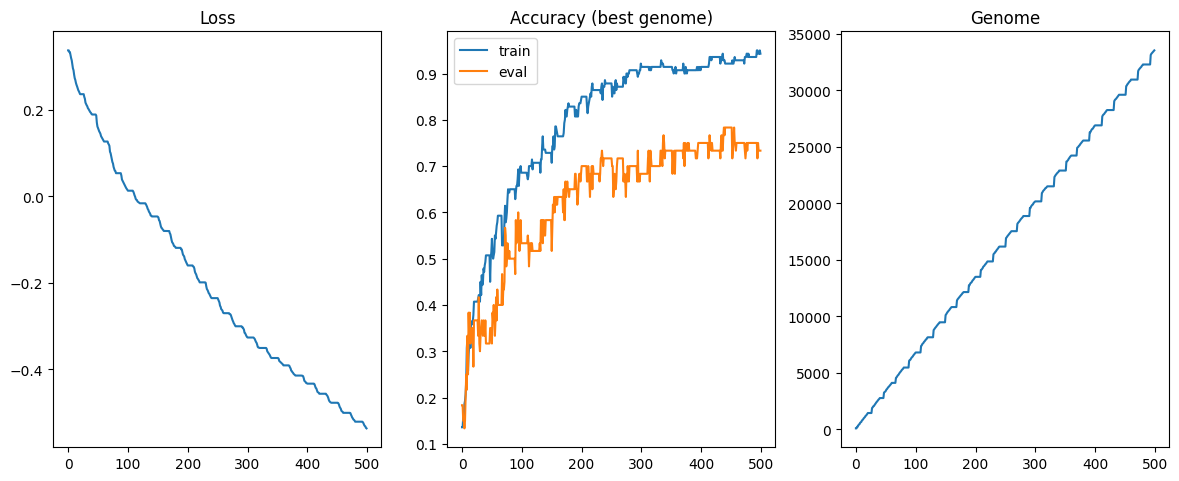

In [31]:
conv_history = train(CONV_POPULATION, EPOCHS, schedulers=SCHEDULERS, use_accuracy=USE_ACCURACY)
# NOTE: the accuracy plot now shows both the train and the held-out eval accuracy of the best genome per epoch

# Evaluation

In [32]:
report_accuracy(CONV_POPULATION, "ConvNetwork (trained)")

ConvNetwork (trained) accuracy [train, eval] x [deterministic, stochastic] x (max, mean): [[(0.95, 0.94), (0.87, 0.82)], [(0.75, 0.74), (0.73, 0.64)]]


[[(0.95, 0.94), (0.87, 0.82)], [(0.75, 0.74), (0.73, 0.64)]]

In [33]:
def get_indices(
    population: Population, images: Tensor, labels: Tensor,
    include: Union[int, list[int]] = None, faulty: int = False, correct: int = False,
    shuffle=True, keys: Union[int, list[int]] = None
):
    model = list(population.modules.values())[0]
    faulty_enabled, correct_enabled = bool(faulty), bool(correct)
    if isinstance(include, (int, float)):
        include = [include]
    if keys is not None and not isinstance(keys, (tuple, list)):
        keys = [keys]

    mapping = population.get_mapping()
    indices = list(range(len(images))) if keys is None else [mapping[key] for key in keys]
    images, labels = images[indices], labels[indices]

    error_indices = []
    if faulty_enabled:
        if isinstance(faulty, bool):
            faulty = 64
        with torch.no_grad():
            for batch in get_batches(labels.shape[1], faulty, False):
                pred = model.evaluate(images[:, batch].to(model.device), keys=keys)
                mismatched = (pred != labels[:, batch].to(model.device)).movedim(0, 1)  # (batch, genomes)
                for index, errored in zip(batch, mismatched):
                    if torch.any(errored):
                        error_indices.append(index)
        print(f"Found {len(error_indices)} record predictions with errors")

    valid_indices = []
    if correct_enabled:
        if isinstance(correct, bool):
            correct = 64
        with torch.no_grad():
            for batch in get_batches(labels.shape[1], correct, False):
                pred = model.evaluate(images[:, batch].to(model.device), keys=keys)
                matched = (pred == labels[:, batch].to(model.device)).movedim(0, 1)  # (batch, genomes)
                for index, is_correct in zip(batch, matched):
                    if torch.any(is_correct):
                        valid_indices.append(index)
        print(f"Found {len(valid_indices)} valid record predictions ")

    indices_filtered = []
    no_type = not correct_enabled and not faulty_enabled
    for g_labels in labels.cpu():
        for x, record in enumerate(g_labels.cpu().tolist()):
            record_needed = include is None or record in include
            spec_type = x in error_indices or x in valid_indices
            if record_needed and (spec_type or no_type):
                indices_filtered.append(x)
    indices_filtered = list(set(indices_filtered))
    if shuffle:
        random.shuffle(indices_filtered)
    if len(indices_filtered) > 0:
        return indices_filtered
    else:
        raise ValueError(f"No indices available")

In [34]:
test_records = 24
CONV_MODEL.eval()

ConvNetwork(
  (sequence): Sequential[NeatModule](
    (0): Conv1d[NeatModule](channels_in=1, channels_out=48, kernel_size=(1,), stride=1, padding=(0,), dilation=1, groups=1, bias=True, padding_mode=zeros)
    (1): SiLU()
    (2): Conv1d[NeatModule](channels_in=48, channels_out=48, kernel_size=(3,), stride=1, padding=(1,), dilation=1, groups=1, bias=False, padding_mode=zeros)
    (3): SiLU()
    (4): Conv1d[NeatModule](channels_in=48, channels_out=48, kernel_size=(3,), stride=1, padding=(1,), dilation=1, groups=1, bias=False, padding_mode=zeros)
    (5): SiLU()
    (6): Conv1d[NeatModule](channels_in=48, channels_out=48, kernel_size=(3,), stride=1, padding=(1,), dilation=1, groups=1, bias=False, padding_mode=zeros)
    (7): SiLU()
    (8): Transpose(dim0=-1, dim1=-2)
    (9): Flatten(start_dim=-2, end_dim=-1)
    (10): Linear[NeatModule](inputs=432, outputs=48, bias=False)
    (11): SiLU()
    (12): Linear[NeatModule](inputs=48, outputs=9, bias=True)
  )
)

In [35]:
train_indices = get_indices(CONV_POPULATION, train_inp, train_out, faulty=None, keys=CONV_POPULATION.best_genome.key)
len(train_indices)

140

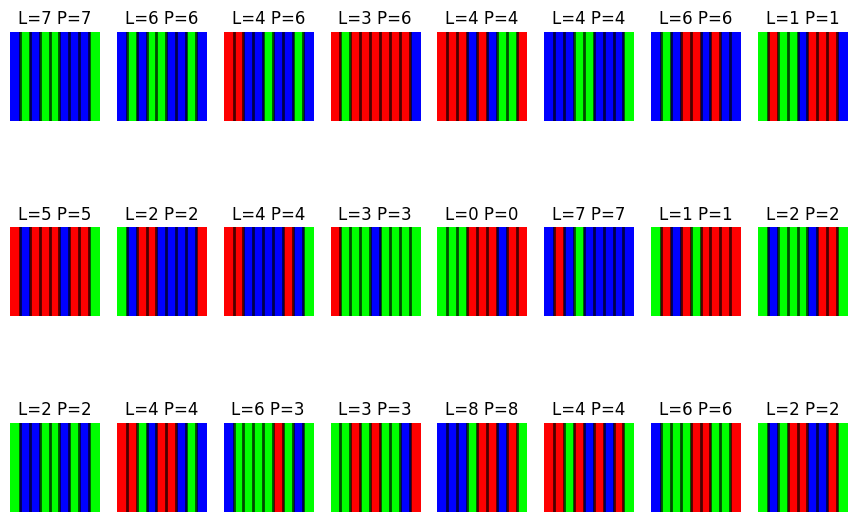

In [36]:
with torch.no_grad():
    random.shuffle(train_indices)
    test_indices = train_indices[:test_records]
    test_labels = CONV_MODEL.evaluate(
        train_inp[0, test_indices].unsqueeze(0).to(DEVICE), keys=CONV_POPULATION.best_genome.key, deterministic=False
    )
show_batch(train_inp[0, test_indices], test_labels[0], train_out[0, test_indices], cmap='brg_r')

In [37]:
eval_indices = get_indices(CONV_POPULATION, eval_inp, eval_out, faulty=None, correct=False)
len(eval_indices)

60

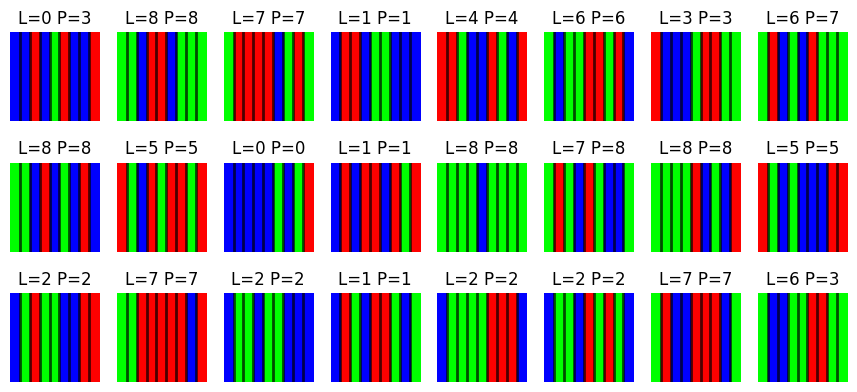

In [38]:
with torch.no_grad():
    random.shuffle(eval_indices)
    test_indices = eval_indices[:test_records]
    test_labels = CONV_MODEL.evaluate(eval_inp[0, test_indices].unsqueeze(0).to(DEVICE), keys=CONV_POPULATION.best_genome.key)
show_batch(
    eval_inp[0, test_indices], test_labels[0], eval_out[0, test_indices],
    cmap='brg', size=(480, 1080),
    compare=False, base=BASE, reverse=REVERSED, normalize=NORMALIZE, discrete=DISCRETE,
)

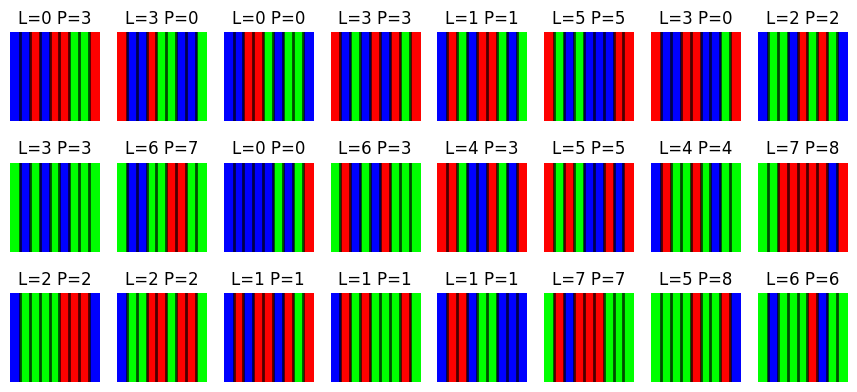

In [39]:
with torch.no_grad():
    random.shuffle(eval_indices)
    test_indices = eval_indices[:test_records]
    test_labels = CONV_MODEL.evaluate(
        eval_inp[0, test_indices].unsqueeze(0).to(DEVICE), keys=CONV_POPULATION.best_genome.key, deterministic=False
    )
show_batch(
    eval_inp[0, test_indices], test_labels[0], eval_out[0, test_indices],
    cmap='brg', size=(480, 1080),
    compare=False, base=BASE, reverse=REVERSED, normalize=NORMALIZE, discrete=DISCRETE,
)

# Linear comparison

In [40]:
LIN_MODEL = LinNetwork(
    INPUTS, OUTPUTS, SEQ_LEN, round(EMBED_SIZE*1.25),
    LAYERS, VOCAB_SIZE, bias=BIAS,
    device=DEVICE, dtype=DTYPE
)
LIN_POPULATION = create_population(LIN_MODEL, GENOMES, CONFIG)
print(f"Genomes={LIN_MODEL.genome_num}, Parameters={model_params(LIN_MODEL)}, Size={model_size(LIN_MODEL):.4f} MB")
LIN_MODEL


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 60 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


Genomes=100, Parameters=4386900, Size=33.4694 MB


LinNetwork(
  (sequence): Sequential[NeatModule](
    (0): Sequential[NeatModule](
      (0): Transpose(dim0=-1, dim1=-2)
      (1): Linear[NeatModule](inputs=1, outputs=60, bias=True)
    )
    (1): SiLU()
    (2): Linear[NeatModule](inputs=60, outputs=60, bias=False)
    (3): SiLU()
    (4): Linear[NeatModule](inputs=60, outputs=60, bias=False)
    (5): SiLU()
    (6): Linear[NeatModule](inputs=60, outputs=60, bias=False)
    (7): SiLU()
    (8): Flatten(start_dim=-2, end_dim=-1)
    (9): Linear[NeatModule](inputs=540, outputs=60, bias=False)
    (10): SiLU()
    (11): Linear[NeatModule](inputs=60, outputs=9, bias=True)
  )
)

In [41]:
report_accuracy(LIN_POPULATION, "LinNetwork (untrained baseline)")

LinNetwork (untrained baseline) accuracy [train, eval] x [deterministic, stochastic] x (max, mean): [[(0.21, 0.11), (0.19, 0.11)], [(0.2, 0.11), (0.23, 0.11)]]


[[(0.21, 0.11), (0.19, 0.11)], [(0.2, 0.11), (0.23, 0.11)]]


Convolutee: (torch.Size([100, 140, 1, 9]))
Predictions: tensor([[[-0.1206,  0.4829,  0.4102,  ..., -0.2187, -0.4533, -0.1041],
         [ 0.0194,  0.5972,  0.4123,  ..., -0.0084, -0.5768, -0.0760],
         [ 0.0042,  0.4487,  0.4498,  ..., -0.0836, -0.6760, -0.0425],
         ...,
         [ 0.0495,  0.1971,  0.1791,  ...,  0.0305, -0.7087,  0.0042],
         [-0.1301,  0.4633,  0.5402,  ..., -0.1088, -0.3845, -0.0066],
         [-0.0504,  0.2272,  0.1453,  ..., -0.0234, -0.7062,  0.2342]],

        [[-0.2300, -0.1360, -0.8160,  ...,  0.2174,  0.0814,  0.0609],
         [-0.3137, -0.2418, -0.6795,  ...,  0.3238,  0.0773,  0.1538],
         [-0.6496, -0.1585, -0.7011,  ...,  0.4718,  0.0595,  0.1646],
         ...,
         [-0.6362, -0.1659, -0.4497,  ...,  0.4468, -0.0112,  0.0157],
         [-0.2533, -0.0731, -0.6752,  ...,  0.0888,  0.0874,  0.1912],
         [-0.4232, -0.1731, -0.4575,  ...,  0.0504,  0.1331,  0.1380]]],
       device='cuda:0', dtype=torch.float64) (torch.Size([1

/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 60 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


NEAT training Epoch(500/500): loss=-1.2413, acc=100.0(63.3)%: progress=100% eta=0sec
finished NEAT training in 753.4s


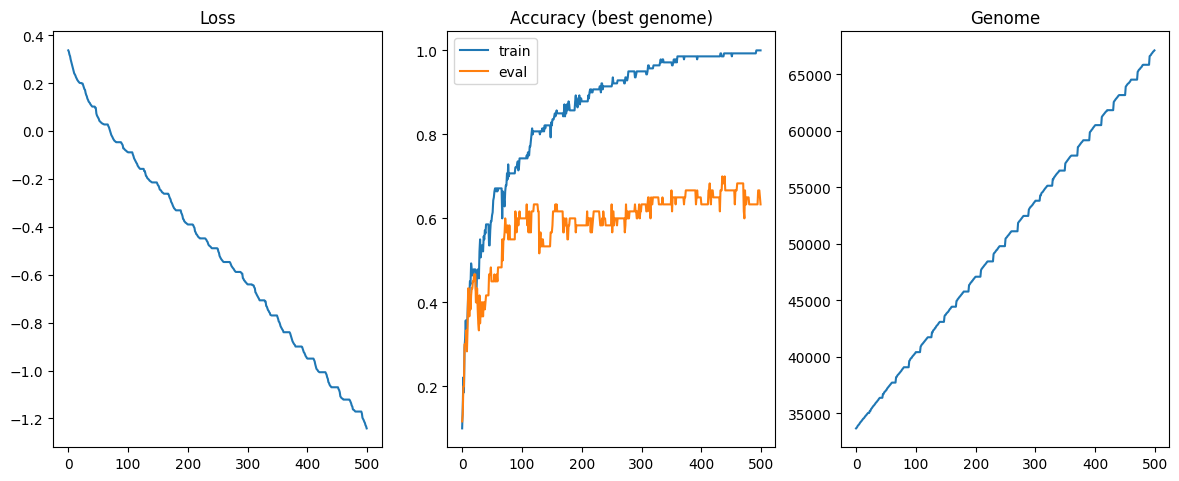

In [42]:
lin_history = train(LIN_POPULATION, EPOCHS, schedulers=SCHEDULERS, use_accuracy=USE_ACCURACY)

In [43]:
report_accuracy(LIN_POPULATION, "LinNetwork (trained)")


LinNetwork (trained) accuracy [train, eval] x [deterministic, stochastic] x (max, mean): [[(1.0, 1.0), (0.98, 0.95)], [(0.7, 0.65), (0.72, 0.64)]]


[[(1.0, 1.0), (0.98, 0.95)], [(0.7, 0.65), (0.72, 0.64)]]

## ConvNetwork vs. LinNetwork
Both models were trained for the same number of epochs, with the same population size, config and
mutation-rate schedulers, so the loss/accuracy curves below are directly comparable.

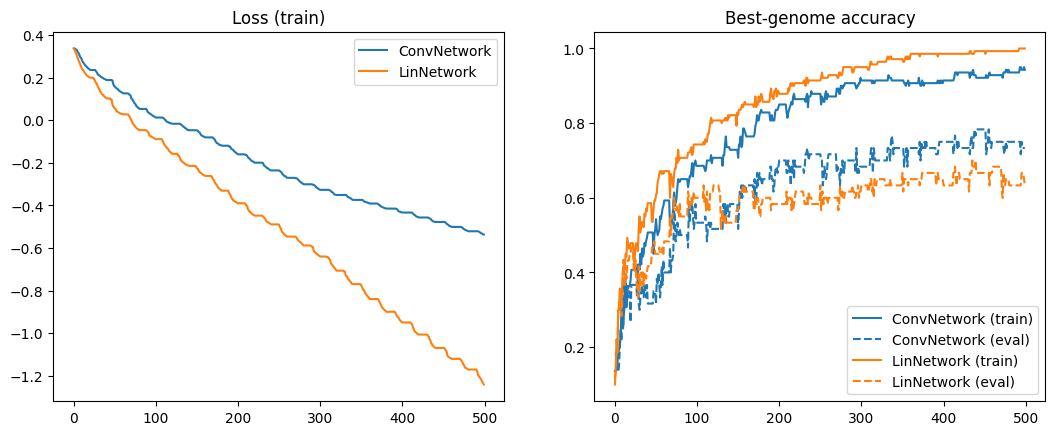

ConvNetwork params = 4200900, LinNetwork params = 4386900


In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12.8, 4.8))
axes[0].plot(conv_history["losses"], label="ConvNetwork")
axes[0].plot(lin_history["losses"], label="LinNetwork")
axes[0].set_title("Loss (train)")
axes[0].legend()

# Solid = train accuracy, dashed = held-out eval accuracy (same colour per model)
for name, history in [("ConvNetwork", conv_history), ("LinNetwork", lin_history)]:
    line, = axes[1].plot(history["accuracies"], label=f"{name} (train)")
    if history.get("eval_accuracies"):
        axes[1].plot(history["eval_accuracies"], "--", color=line.get_color(), label=f"{name} (eval)")
axes[1].set_title("Best-genome accuracy")
axes[1].legend()
plt.show()

print(f"ConvNetwork params = {model_params(CONV_MODEL)}, LinNetwork params = {model_params(LIN_MODEL)}")


Observations and conclusions (updated from the Colab run: `CLASSES=9`, `PAD_LEN=7`, 5% noise, no pooling, bias off, 100 genomes x 500 epochs; ConvNetwork 42,009 vs LinNetwork 43,869 parameters per genome)


**From the latest run**

1. The linear model fits the training set better, but the convolutional model generalizes better. LinNetwork reaches 100% train accuracy and a much lower loss (log10 loss -1.24 vs -0.54 for ConvNetwork), yet its best genome ends at 63.3% eval accuracy against 73.3% for ConvNetwork (94.3% train). Eval accuracy flattens after roughly epoch 250 for both while train accuracy keeps rising, most clearly for LinNetwork. This replaces the earlier "linear model has higher accuracy", which only holds on train.
2. `report_accuracy` takes the max over genomes on the split it evaluates, so its eval numbers (Conv 0.75, Lin 0.70) are optimistic. For comparing models, prefer the best-genome-by-train eval accuracy from the training log (73.3% vs 63.3%). Eval has only 60 records (one record is 1.7 points) and there is a single run per model, so the roughly 10 point gap is suggestive, not conclusive.
3. Neither model has converged: the log10 loss is still falling roughly linearly at epoch 500. Eval accuracy of 63-75% is also well below what the data allows. A record has 2 informative digits (9 classes, base 3) and each position is replaced by a random digit with probability 0.05 * 2/3 = 3.3%, so about 93% of records still carry an intact pattern (back-of-envelope estimate, not measured). The gap suggests the models partly fit the noise and distractor positions of the 140 train records instead of the rule.
4. More genomes with fewer epochs was cheaper in time here: 200 x 250 took 488 s against 788 s for 100 x 500 (-38%), even though each epoch is about 24% slower (1.95 s vs 1.58 s). The log's GPU under-utilization warnings at 100 genomes fit with the larger population using the GPU better. Train accuracy stayed close (92.1% vs 94.3%) and eval accuracy was higher (80.0% vs 73.3%), but that is a 4 record difference from one run, so the time saving is the more reliable part.

**Carried over from earlier runs (not re-tested in the latest run)**

5. Lack of normalization, at least for simple models like this, seems to work better. Possibly due to the somewhat stochastic/randomized nature of fitting the weights, making it easier to find solutions even with the raw/un-normalized tensors, unlike with backprop.
6. Reduction of loss, especially on the convolutional models, is highly dependant on weight initialization range and weight mutation parameters, and seems to scale with the dimension size of layers. When too high, reduction is difficult since no back-propagation. When too low, it seems to take extremly long.
7. With bias disabled, the models seem to reduce the loss better. Might just be due less parameters involved. Recent versions of NEAT generates values of weight and bias with the same constant, unlike older versions (ie. All model parameters are considered weights). So it must be easier to adjust weights alone when its the only direct benefactor to the mutate constant than with biases that typically need a separate constant.
8. Models seem to converge better on discrete states with embedding layers rather than continuous states (this run used `DISCRETE = False`).


# Genomes vs Epochs

/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 100 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 20 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))



Convolutee: (torch.Size([200, 140, 1, 9]))
Predictions: tensor([[[-0.4331,  0.1075,  0.4724,  ...,  0.8661, -0.2080,  0.0578],
         [-0.1402, -0.1785, -0.4319,  ..., -0.8627,  0.3521,  0.4362],
         [-1.7593, -0.8290,  1.3772,  ..., -0.5678,  0.0442,  0.5680],
         ...,
         [-0.7818,  0.5412, -0.2970,  ...,  0.0841,  0.0356, -1.0480],
         [ 0.7969,  0.5152, -0.7422,  ...,  0.8503,  0.6671, -0.5802],
         [ 0.2429, -0.6406,  0.1457,  ..., -0.5691,  0.1729,  0.4298]],

        [[-0.1418,  0.1667, -0.5881,  ...,  0.1248, -0.2214, -1.6397],
         [ 0.0475, -0.4086, -1.1709,  ...,  0.6542, -0.4705, -1.2899],
         [-1.1273, -0.6689, -1.2353,  ...,  0.3152, -1.2543, -1.7300],
         ...,
         [-0.1720,  0.5610, -0.3891,  ..., -0.2281, -0.5638, -1.8084],
         [-0.1923,  0.1923,  0.3503,  ...,  0.5593,  0.2112, -2.3450],
         [-0.4495, -0.7643, -1.2387,  ...,  0.5383, -1.2663, -2.2306]]],
       device='cuda:0', dtype=torch.float64) (torch.Size([2

/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 100 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 20 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


NEAT training Epoch(250/250): loss=-0.3392, acc=92.1(80.0)%: progress=100% eta=0sec
finished NEAT training in 488.5s
 genomes  epochs  time (s)  train acc  eval acc
     100     500     788.2       0.95      0.75
     200     250     488.5       0.94      0.83


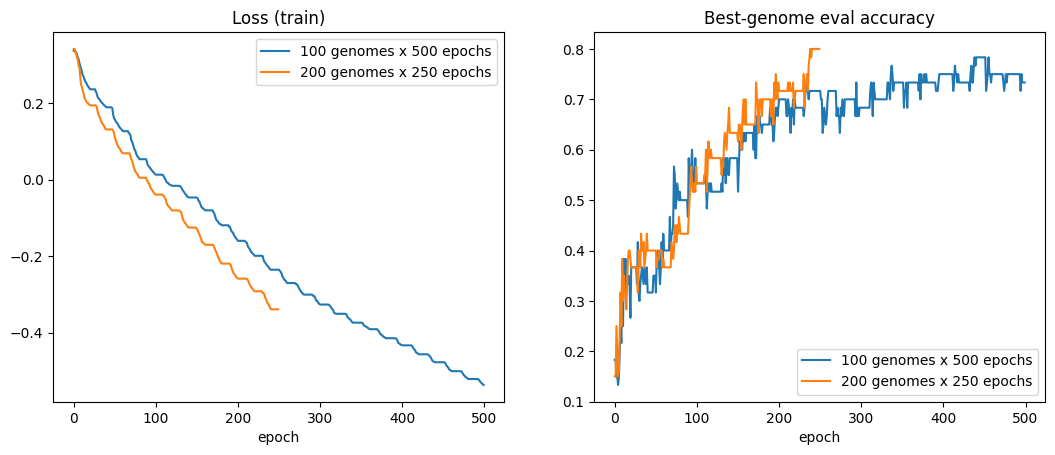

In [46]:
# Does doubling the genomes while halving the epochs reach a similar accuracy in less time?
# (The batched/parallel backend may handle more genomes per epoch far more cheaply than linearly.)
# NOTE: Needs `conv_history` / `CONV_POPULATION` from the training run above; its numbers are the baseline.

def run_budget_experiment(genomes: int, epochs: int, seed: int = 0):
    """Trains a fresh ConvNetwork population of `genomes` for `epochs` and returns its summary."""
    torch.manual_seed(seed); random.seed(seed)
    train_set, eval_set = get_records(genomes, SPLIT)
    min_species_size = CONFIG.reproduction.min_species_size
    CONFIG.reproduction.min_species_size = genomes  # config ties this to the population size
    try:
        model = ConvNetwork(
            INPUTS, OUTPUTS, EMBED_SIZE, KERNEL_SIZE, SEQ_LEN,
            LAYERS, VOCAB_SIZE, GROUPS, bias=BIAS, device=DEVICE, dtype=DTYPE
        )
        population = create_population(model, genomes, CONFIG)
        history = train(
            population, epochs, schedulers=SCHEDULERS, show=False,
            train_set=train_set, eval_set=eval_set
        )
        summary = {
            "genomes": genomes, "epochs": epochs, "elapsed": history["elapsed"],
            "train_acc": get_accuracy(population, *train_set, BATCH_SIZE),
            "eval_acc": get_accuracy(population, *eval_set, BATCH_SIZE),
            "history": history,
        }
    finally:
        CONFIG.reproduction.min_species_size = min_species_size
    return summary

# Baseline = the already trained CONV_POPULATION (GENOMES genomes x EPOCHS epochs)
baseline = {
    "genomes": GENOMES, "epochs": EPOCHS, "elapsed": conv_history["elapsed"],
    "train_acc": get_accuracy(CONV_POPULATION, *train_data, BATCH_SIZE),
    "eval_acc": get_accuracy(CONV_POPULATION, *eval_data, BATCH_SIZE),
    "history": conv_history,
}
doubled = run_budget_experiment(GENOMES * 2, EPOCHS // 2)

print(f"{'genomes':>8} {'epochs':>7} {'time (s)':>9} {'train acc':>10} {'eval acc':>9}")
for r in (baseline, doubled):
    print(f"{r['genomes']:>8} {r['epochs']:>7} {r['elapsed']:>9.1f} {r['train_acc']:>10.2f} {r['eval_acc']:>9.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12.8, 4.8))
for r in (baseline, doubled):
    label = f"{r['genomes']} genomes x {r['epochs']} epochs"
    axes[0].plot(r["history"]["losses"], label=label)
    axes[1].plot(r["history"]["eval_accuracies"], label=label)
axes[0].set_title("Loss (train)"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].set_title("Best-genome eval accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.show()
